# Trabalho 2 — 01 · RAG Data Preparation
### Pokédex Inteligente · 151 Pokémon de Kanto / FireRed

**Responsabilidade exclusiva:** ler o corpus bruto enriquecido pelo notebook `CORPUS_POKEMON_COLETA_ENRIQUECIDA.ipynb`, validar integridade e converter seus atributos em **documentos temáticos para recuperação e contexto do LLM**.

**Este notebook não consulta a PokéAPI, não altera dados brutos e não treina modelo.** O Notebook 02 fará TF-IDF, ranking e avaliação.

## 0 · Ambiente, caminhos e dependências

A pasta `corpus` contém os 151 arquivos brutos com `enrichment`. Os resultados ficam exclusivamente em `application`. A preparação pode ser executada **offline após os arquivos estarem disponíveis no Drive**.

In [39]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib, json, logging, re, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk import pos_tag
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount('/content/drive')

AVALIACAO_DIR = (Path('/content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao')
                 if IN_COLAB else Path.cwd())
SOURCE_DIR = AVALIACAO_DIR / 'corpus'
RAW_DIR = SOURCE_DIR / 'corpus_data_firered' / 'raw_data'
APPLICATION_DIR = AVALIACAO_DIR / 'application'
RAG_DIR = APPLICATION_DIR / 'data' / 'rag'
DOC_DIR = RAG_DIR / 'documents'
REFERENCE_DIR = RAG_DIR / 'reference'
REPORT_DIR = APPLICATION_DIR / 'reports'
LOG_DIR = APPLICATION_DIR / 'logs'
for folder in (DOC_DIR, REFERENCE_DIR, REPORT_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

EXPECTED_IDS = set(range(1,152))
FIRERED_VERSION = 'firered'
FIRERED_VERSION_GROUP = 'firered-leafgreen'
ENRICHMENT_SCHEMA_VERSION = '1.0'
RUN_AT = datetime.now(timezone.utc).isoformat()
print('Origem (somente leitura):', RAW_DIR)
print('Saída RAG:', RAG_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Origem (somente leitura): /content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/corpus/corpus_data_firered/raw_data
Saída RAG: /content/drive/MyDrive/IFSP-ADS/ultimo_periodo/tc_2/avaliacao/application/data/rag


## 1 · Preparação linguística e logs

Mantemos a normalização, tokenização, stopwords, POS tagging e lematização do Trabalho 1 para construir textos de recuperação. O `content` permanece legível para o modelo generativo.

In [40]:
logger = logging.getLogger('pokemon_rag_data')
logger.handlers.clear()
logger.setLevel(logging.INFO)
logger.propagate = False
formatter = logging.Formatter('%(asctime)s | %(levelname)s | %(message)s')
file_handler = logging.FileHandler(LOG_DIR / '01_rag_data_preparation.log', encoding='utf-8')
file_handler.setFormatter(formatter)
logger.addHandler(file_handler)
stream_handler = logging.StreamHandler()
stream_handler.setLevel(logging.WARNING)
stream_handler.setFormatter(formatter)
logger.addHandler(stream_handler)
logger.info('Início da preparação RAG | origem=%s', RAW_DIR)

for resource in ('punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4',
                 'averaged_perceptron_tagger_eng'):
    nltk.download(resource, quiet=True)
STOPWORDS_EN = set(stopwords.words('english'))
LEMMATIZER = WordNetLemmatizer()

def normalize_text(value):
    value = unicodedata.normalize('NFC', str(value or '')).lower()
    return re.sub(r'\s+', ' ', value.replace('\f', ' ').replace('\n',' ')).strip()

def normalize_domain_phrase(value):
    text = normalize_text(value).replace('-', ' ')
    text = ''.join(ch for ch in unicodedata.normalize('NFKD',text) if not unicodedata.combining(ch))
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9_\s]', ' ', text)).strip()

def wordnet_pos(tag):
    return {'J': wordnet.ADJ, 'V': wordnet.VERB, 'N': wordnet.NOUN,
            'R': wordnet.ADV}.get(tag[:1], wordnet.NOUN)

def preprocess_description(value):
    tokens = [token.lower() for token in word_tokenize(normalize_text(value))
              if token.isalpha()]
    tokens = [token for token in tokens if token not in STOPWORDS_EN]
    return [LEMMATIZER.lemmatize(token, wordnet_pos(tag))
            for token, tag in pos_tag(tokens)] if tokens else []

def clean_label(value):
    return str(value or '').replace('-', ' ').strip()

def sha256_file(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

logger.info('Preparação linguística iniciada (sem consultas externas)')

## 2 · Leitura e validação dos 151 arquivos enriquecidos

Exigimos a chave `enrichment` com versão de esquema correta. Se faltar, execute antes a seção de enriquecimento do notebook do corpus.

In [41]:
if not RAW_DIR.is_dir():
    raise FileNotFoundError(f'Diretório bruto não encontrado: {RAW_DIR}')
bundles, errors = [], []
for pokemon_id in range(1,152):
    path = RAW_DIR / f'{pokemon_id:03d}.json'
    try:
        raw = json.loads(path.read_text(encoding='utf-8'))
        if int(raw['id']) != pokemon_id or int(raw['pokemon']['id']) != pokemon_id:
            raise ValueError('ID inconsistente no JSON original')
        for key in ('pokemon','species','evolution_chain','encounters'):
            if key not in raw: raise ValueError('Chave original ausente: '+key)
        extra = raw.get('enrichment') or {}
        if extra.get('schema_version') != ENRICHMENT_SCHEMA_VERSION:
            raise ValueError('Enriquecimento inexistente ou em versão incompatível. Rode o notebook do corpus.')
        data = extra.get('data') or {}
        if int(data.get('id',-1)) != pokemon_id:
            raise ValueError('Registro enriquecido com ID incorreto')
        bundles.append({'id':pokemon_id,'bundle':raw,'source_file':path.name,
                        'source_sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
    except Exception as exc:
        errors.append({'id':pokemon_id,'arquivo':path.name,'erro':str(exc)})
print(f'Bundles prontos: {len(bundles)}/151 | inconsistências: {len(errors)}')
if errors:
    display(pd.DataFrame(errors).head(20))
    raise RuntimeError('Falha de validação: complete a coleta no notebook do corpus antes de continuar.')
assert {b['id'] for b in bundles} == EXPECTED_IDS

Bundles prontos: 151/151 | inconsistências: 0


## 3 · Equivalências PT-BR / inglês

Os aliases ajudam a normalizar consultas em português para os termos utilizados pela PokéAPI. Eles são aproximações terminológicas, não traduções oficiais do jogo.

In [42]:
TYPE_PTBR = {
    'normal':'normal', 'fighting':'lutador', 'flying':'voador',
    'poison':'venenoso', 'ground':'terrestre', 'rock':'pedra',
    'bug':'inseto', 'ghost':'fantasma', 'steel':'aço',
    'fire':'fogo', 'water':'água', 'grass':'planta',
    'electric':'elétrico', 'psychic':'psíquico', 'ice':'gelo',
    'dragon':'dragão', 'dark':'sombrio'
}
TYPE_ALIASES = {
    'fighting':['lutador','luta'], 'flying':['voador','voando'],
    'poison':['venenoso','veneno'], 'ground':['terrestre','terra'],
    'rock':['pedra','rocha'], 'bug':['inseto'], 'ghost':['fantasma'],
    'steel':['aço','metal'], 'fire':['fogo'], 'water':['água'],
    'grass':['planta','grama'], 'electric':['elétrico','eletrico'],
    'psychic':['psíquico','psiquico'], 'ice':['gelo'],
    'dragon':['dragão','dragao'], 'dark':['sombrio','escuridão']
}
QUERY_ALIASES_PTBR = {
    'evolução':'evolution', 'evoluções':'evolutions', 'evolui':'evolves',
    'fraqueza':'weakness', 'fraquezas':'weaknesses',
    'resistência':'resistance', 'resistências':'resistances',
    'imunidade':'immunity', 'imunidades':'immunities',
    'golpe':'move', 'golpes':'moves', 'ataque':'attack',
    'defesa':'defense', 'velocidade':'speed', 'habilidade':'ability',
    'habilidades':'abilities', 'localização':'location',
    'localizações':'locations', 'encontrar':'encounter',
    'capturar':'capture', 'nível':'level', 'pedra':'stone',
    'troca':'trade', 'tipo':'type', 'tipos':'types',
    'peso':'weight', 'altura':'height', 'vida':'hp',
    'surfar':'surf', 'raio solar':'solar beam', 'lança chamas':'flamethrower'
}

# Exportado em formato explícito para o mecanismo lexical do Notebook 02.
translations = {'types_en_ptbr': TYPE_PTBR, 'type_aliases_ptbr': TYPE_ALIASES,
                'query_aliases_ptbr_en': QUERY_ALIASES_PTBR,
                'note': 'aliases experimentais para recuperação lexical; não são traduções oficiais.'}
(REFERENCE_DIR / 'translation_aliases_ptbr_en.json').write_text(
    json.dumps(translations, indent=2, ensure_ascii=False), encoding='utf-8')
print('Tipos da geração III:', len(TYPE_PTBR))

Tipos da geração III: 17


## 4 · Conversão dos bundles enriquecidos em registros RAG

Esta etapa **não recalcula** evoluções, fraquezas, habilidades ou golpes. Apenas lê o bloco `enrichment.data` produzido pelo notebook de coleta. Cada registro conserva informações de proveniência e o SHA-256 de seu arquivo bruto.

In [43]:
def clean_record(item):
    raw = item['bundle']
    data = dict(raw['enrichment']['data'])
    data['source_file'] = item['source_file']
    data['source_sha256'] = item['source_sha256']
    data['enrichment_schema_version'] = raw['enrichment']['schema_version']
    data['enriched_at_utc'] = raw['enrichment'].get('generated_at_utc')
    return data

records = sorted((clean_record(b) for b in bundles), key=lambda r:r['id'])
assert len(records)==151
assert all(r['types_gen3'] and r['stats_gen3'] and r['name'] for r in records)
assert all(r['provenance'] and r['source_file'] and r['source_sha256'] for r in records)
display(pd.DataFrame([{
    'id':r['id'], 'name':r['name'],
    'types':', '.join(r['types_gen3']),
    'stats':len(r['stats_gen3']),
    'abilities':len(r['abilities_gen3']),
    'moves':len(r['moves_frlg']),
    'wild_encounters':len(r['encounters_firered'])
} for r in records]).head(10))
logger.info('Importados %d registros enriquecidos dos arquivos brutos', len(records))

,id,name,types,stats,abilities,moves,wild_encounters
0,1,Bulbasaur,"grass, poison",6,1,43,1
1,2,Ivysaur,"grass, poison",6,1,37,0
2,3,Venusaur,"grass, poison",6,1,42,0
3,4,Charmander,fire,6,1,51,1
4,5,Charmeleon,fire,6,1,44,0
5,6,Charizard,"fire, flying",6,1,53,0
6,7,Squirtle,water,6,1,51,1
7,8,Wartortle,water,6,1,45,0
8,9,Blastoise,water,6,1,50,0
9,10,Caterpie,bug,6,1,2,8


## 5 · Documentos temáticos para o RAG

Cada Pokémon produz documentos de perfil, atributos, habilidades, efetividade defensiva, evolução, golpes, encontros e obtenção. `retrieval_text` favorece busca lexical; `content` conserva descrições factuais e legíveis.

Relacionamentos evolutivos fora dos 151 Pokémon ficam fora do escopo. Condições de evolução retornadas por endpoint não versionado são tratadas como **não verificadas especificamente para FireRed**.

In [44]:
def evolution_condition_text(option):
    if not option:return 'condition unspecified by API'
    labels={'trigger':'trigger','min_level':'minimum level','item':'item',
            'held_item':'held item','min_happiness':'minimum friendship',
            'min_beauty':'minimum beauty','known_move':'known move',
            'trade_species':'trade species','time_of_day':'time of day',
            'gender':'gender code','relative_physical_stats':'relative stats',
            'location':'location','party_species':'party species',
            'party_type':'party type'}
    return '; '.join(f'{labels.get(k,k)}: {str(v).replace("-"," ")}'
                     for k,v in option.items())

In [45]:
def make_chunk(r,section,lines,part=None,keywords=(),scope='kanto_gen3'):
    content='\n'.join(str(x) for x in lines if x is not None).strip()
    if not content:return None
    doc_id=f"{r['id']:03d}_{section}" + (f'_{part:02d}' if part is not None else '')
    enriched_terms=[r['api_name'],r['name'],section,*keywords]
    if section=='profile':
        enriched_terms += [TYPE_PTBR.get(t,'') for t in r['types_gen3']]
        enriched_terms += preprocess_description(r['description'])
    retrieval_text=' '.join(normalize_domain_phrase(x) for x in enriched_terms+lines if x).strip()
    return {'document_id':doc_id,'pokemon_id':r['id'],'pokemon_name':r['name'],
            'section':section,'content':content,'retrieval_text':retrieval_text,
            'factual_scope':scope,'source_file':r['source_file'],
            'source_sha256':r['source_sha256'],'provenance':r['provenance']}


def chunks_for_record(r):
    out=[]
    def put(section,lines,part=None,keywords=(),scope='kanto_gen3'):
        c=make_chunk(r,section,lines,part,keywords,scope)
        if c:out.append(c)

    put('profile',[f"Pokémon {r['name']} (National Pokédex #{r['id']:03d}).",
                   f"Types in Generation III: {', '.join(r['types_gen3'])}.",
                   f"Types PT-BR: {', '.join(TYPE_PTBR[t] for t in r['types_gen3'])}.",
                   f"Pokédex description ({r['description_version']}): {r['description'] or 'not available'}.",
                   f"Habitat: {r['habitat'] or 'not recorded'}.",
                   f"Height: {r['height_m']} m; weight: {r['weight_kg']} kg.",
                   f"Capture rate (API): {r['capture_rate']}."],keywords=r['types_gen3'])

    breeding=[f"Species/breeding attributes of {r['name']} (PokéAPI species metadata):",
              f"Egg groups: {', '.join(r['egg_groups']) or 'not recorded'}.",
              f"Gender rate code: {r['gender_rate']} (-1 means genderless).",
              f"Growth rate: {r['growth_rate'] or 'not recorded'}.",
              f"Color: {r['color'] or 'not recorded'}."]
    put('species_traits',breeding,keywords=['egg group','gênero','breeding','growth rate'])

    stat_lines=[f"Base stats for {r['name']} (Generation III reconstructed from PokéAPI):"]
    for key,value in sorted(r['stats_gen3'].items()):
        stat_lines.append(f'- {clean_label(key)}: {value}.')
    put('stats',stat_lines,keywords=['hp','attack','defense','speed','special attack','special defense'])

    ability_lines=[f"Abilities of {r['name']} reconstructed for Generation III:"]
    if r['abilities_gen3']:
        for ability in r['abilities_gen3']:
            ability_lines.append(f"- {clean_label(ability['name'])} (slot {ability['slot']}; {ability['verification']}).")
    else:
        ability_lines.append('Not reliably established from this API snapshot.')
    put('abilities',ability_lines,keywords=['ability','abilities'])

    chart=r['defensive_type_matchups_gen3']
    if chart:
        matchups=[f"Defensive effectiveness against {r['name']} (Generation III type chart):"]
        for tag,label in [('x4','4x weak'),('x2','2x weak'),('x0_5','0.5x resistant'),
                          ('x0_25','0.25x resistant'),('x0','immune (0x)')]:
            if chart[tag]:matchups.append(f"- {label}: {', '.join(chart[tag])}.")
        matchups.append('Type chart only: abilities and battle conditions may modify damage.')
        put('type_matchups',matchups,keywords=['weakness','resistance','immune','fraqueza','resistência'])

    if r['evolution_members_kanto']:
        ev=[f"Evolution family of {r['name']} (only species 1–151): " +
            ', '.join(x['name'] for x in r['evolution_members_kanto']) + '.']

        # Identifica se o Pokémon possui uma pré-evolução.
        incoming_edges = [
            edge for edge in r['evolution_edges_kanto']
            if edge["to_id"] == r["id"]
        ]
        if incoming_edges:
            for edge in incoming_edges:
                previous = clean_label(edge["from_name"]).title()
                ev.append(
                    f"{r['name']} evolves from {previous}."
                )
        elif not r.get("evolution_members_outside_kanto"):
            # Só afirma que é forma inicial quando a família
            # documentada não possui espécies externas a Kanto.
            ev.append(
                f"{r['name']} is the first stage of its evolution "
                f"family and does not evolve from another Pokémon."
            )

        # Condições de evolução detalhadas da família
        for edge in r['evolution_edges_kanto']:
            options=' OR '.join('(' + evolution_condition_text(op) + ')' for op in edge['conditions_or'])
            ev.append(f"- {edge['from_name']} -> {edge['to_name']}. Conditions: {options or 'not recorded'}. Not specifically verified for FireRed.")

        ev.append('Evolution of later-generation species is intentionally outside the Kanto scope.')
        put('evolution',ev,keywords=[x['name'] for x in r['evolution_members_kanto']],
            scope='kanto_species_evolution_conditions_unversioned')

    # 15 movimentos por documento, evitando chunks muito longos.
    move_rows=r['moves_frlg']
    for offset in range(0,len(move_rows),15):
        subset=move_rows[offset:offset+15]
        lines=[f"Moves learnable by {r['name']} (FireRed/LeafGreen version group):"]
        for m in subset:
            d=m['move_data'];suffix=''
            if m['method']=='level-up':suffix=f"; level {m['level_learned_at']}"
            elif m['method']=='machine':suffix=f"; machines: {', '.join(m.get('tm_hm',[])) or 'TM/HM unresolved'}"
            if d.get('data_status')=='available':
                suffix+=f"; type: {d['type']}; power: {d['power']}; accuracy: {d['accuracy']}; "
                suffix+=f"PP: {d['pp']}; gen3 category: {d['damage_class_gen3']}"
            else:suffix+='; move metadata unavailable'
            lines.append(f"- {clean_label(m['name'])}: {clean_label(m['method'])}{suffix}.")
        put('moves',lines,part=1+offset//15,
            keywords=['moves','golpes','level up','tm hm']+[m['name'] for m in subset],
            scope='firered_leafgreen_learnset_with_pokeapi_move_history')

    if r['encounters_firered']:
        encounter_rows=r['encounters_firered']
        for offset in range(0,len(encounter_rows),15):
            lines=[f"Documented wild encounters for {r['name']} in Pokémon FireRed:"]
            for e in encounter_rows[offset:offset+15]:
                lines.append(f"- {clean_label(e['area'])}; method: {clean_label(e['method'])}; "
                             f"levels: {e['min_level']}-{e['max_level']}; "
                             f"API encounter chance weight: {e['chance_weight']}; "
                             f"conditions: {', '.join(e['condition_values']) or 'not specified'}.")
            lines.append('This list does not cover gifts, trades, evolution or fossils.')
            put('encounters',lines,part=1+offset//15,
                keywords=['where','location','route','encontrar','capturar'],scope='wild_encounters_firered')

    available=r['obtainment']['documented_mechanisms']
    obtainment=[f"Acquisition evidence for {r['name']} in FireRed:",
                f"Documented mechanisms: {', '.join(available) if available else 'none in API encounter records'}.",
                'Complete game availability is NOT established from this dataset.',
                'No wild encounter entry does not imply unavailable; gifts, fossils, NPC trades and external trades need independently verified sources.']
    put('obtainment',obtainment,keywords=['obtain','get','wild','starter','trade','gift','exchange'],
        scope='partial_availability_evidence')
    return out

## 6 · Inspeção visual

Consulte os documentos temáticos de um Pokémon (Charizard por padrão). As informações foram extraídas dos JSONs brutos enriquecidos, sem acessar a API.

In [46]:
# Garante que a variável chunks seja definida a partir dos records e da função chunks_for_record
if 'records' in globals() and 'chunks_for_record' in globals():
    chunks = [d for r in records for d in chunks_for_record(r)]

EXAMPLE_POKEMON = 6
for c in [x for x in chunks if x['pokemon_id']==EXAMPLE_POKEMON]:
    if c['section']=='moves' and not c['document_id'].endswith('_01'): continue
    print('\n'+('='*64)+'\n',c['document_id'],'|',c['factual_scope'])
    print(c['content'][:1000] + ('...' if len(c['content'])>1000 else ''))


 006_profile | kanto_gen3
Pokémon Charizard (National Pokédex #006).
Types in Generation III: fire, flying.
Types PT-BR: fogo, voador.
Pokédex description (firered): Its wings can carry this POKéMON close to an altitude of 4,600 feet. It blows out fire at very high temperatures..
Habitat: mountain.
Height: 1.7 m; weight: 90.5 kg.
Capture rate (API): 45.

 006_species_traits | kanto_gen3
Species/breeding attributes of Charizard (PokéAPI species metadata):
Egg groups: monster, dragon.
Gender rate code: 1 (-1 means genderless).
Growth rate: medium-slow.
Color: red.

 006_stats | kanto_gen3
Base stats for Charizard (Generation III reconstructed from PokéAPI):
- attack: 84.
- defense: 78.
- hp: 78.
- special attack: 109.
- special defense: 85.
- speed: 100.

 006_abilities | kanto_gen3
Abilities of Charizard reconstructed for Generation III:
- blaze (slot 1; generation_iii_reconstructed).

 006_type_matchups | kanto_gen3
Defensive effectiveness against Charizard (Generation III type chart)

## 7 · Relatório de qualidade e cobertura

Cobertura mede apenas o preenchimento de campos. Não garante a fidelidade histórica dos snapshots da PokéAPI, nem disponibilidade completa dos Pokémon no FireRed.

In [47]:
sections = Counter(x['section'] for x in chunks)
coverage = {
    'pokemon_expected':151, 'pokemon_loaded':len(records), 'documents':len(chunks),
    'exact_firered_descriptions':sum(r['description_version']=='firered' for r in records),
    'fallback_descriptions':sum(r['description_version'] not in ('firered','missing') for r in records),
    'with_full_six_base_stats':sum(len(r['stats_gen3'])==6 for r in records),
    'with_abilities_gen3':sum(bool(r['abilities_gen3']) for r in records),
    'with_type_matchups_gen3':sum(bool(r['defensive_type_matchups_gen3']) for r in records),
    'with_evolution_edges_unversioned':sum(bool(r['evolution_edges_kanto']) for r in records),
    'with_moves_frlg':sum(bool(r['moves_frlg']) for r in records),
    'with_wild_encounters_firered':sum(bool(r['encounters_firered']) for r in records),
    'total_moves_with_missing_metadata':sum(
        m['move_data'].get('data_status')!='available'
        for r in records for m in r['moves_frlg']),
    'total_unresolved_tm_hm_entries':sum(
        m['method']=='machine' and not m.get('tm_hm')
        for r in records for m in r['moves_frlg']),
}
report = {
    'title':'Pokédex Inteligente — preparação de documentos RAG',
    'run_utc':RUN_AT,
    'source_raw_dir':str(RAW_DIR),
    'output_dir':str(RAG_DIR),
    'coverage':coverage,
    'documents_by_section':dict(sections),
    'enrichment_schema_version':ENRICHMENT_SCHEMA_VERSION,
    'limitations':[
        'Condições de evolução não são específicas da versão FireRed.',
        'Ausência de encontro selvagem não significa indisponibilidade no jogo.',
        'A reconstrução histórica foi realizada no notebook do corpus.',
        'Aliases PT-BR são equivalências experimentais.',
    ],
}
display(pd.DataFrame([coverage]).T.rename(columns={0:'valor'}))
logger.info('Cobertura RAG | %s',coverage)

,valor
pokemon_expected,151
pokemon_loaded,151
documents,1732
exact_firered_descriptions,151
fallback_descriptions,0
with_full_six_base_stats,151
with_abilities_gen3,151
with_type_matchups_gen3,151
with_evolution_edges_unversioned,126
with_moves_frlg,151


## 8 · Visualização diagnóstica

Esta visualização resume a quantidade de documentos por seção. Os gráficos de avaliação do recuperador serão implementados no Notebook 02.

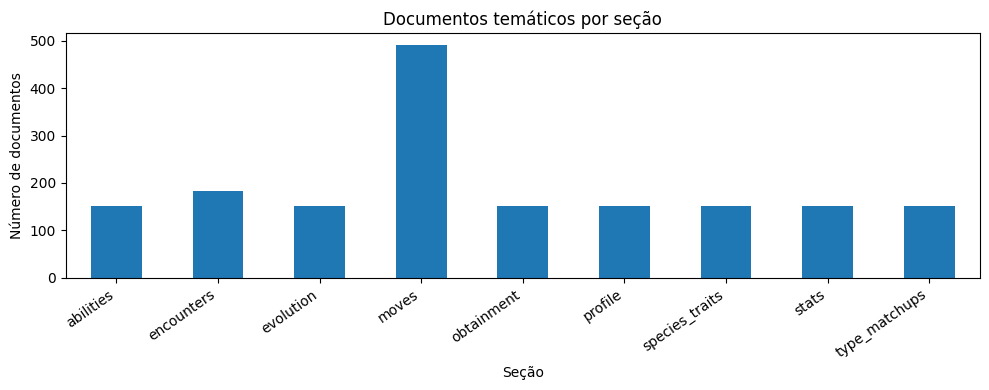

In [48]:
summary=pd.Series(sections).sort_index()
ax=summary.plot.bar(figsize=(10,4),title='Documentos temáticos por seção')
ax.set(xlabel='Seção',ylabel='Número de documentos')
plt.xticks(rotation=35,ha='right')
plt.tight_layout()
plt.show()

## 9 · Exportação dos artefatos

- `application/data/rag/documents/pokemon_rag_records.jsonl` — registros enriquecidos, um por Pokémon.
- `application/data/rag/documents/pokemon_rag_documents.jsonl` — chunks temáticos para TF-IDF e RAG.
- `application/data/rag/documents/pokemon_rag_metadata.csv` — resumo tabular.
- `application/reports/data_quality_report.json` — diagnóstico.
- `application/data/rag/reference/translation_aliases_ptbr_en.json` — equivalências de consulta.

In [49]:
def write_jsonl(path,rows):
    with path.open('w',encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row,ensure_ascii=False,sort_keys=True)+'\n')

doc_path=DOC_DIR/'pokemon_rag_documents.jsonl'
record_path=DOC_DIR/'pokemon_rag_records.jsonl'
metadata_path=DOC_DIR/'pokemon_rag_metadata.csv'
report_path=REPORT_DIR/'data_quality_report.json'
write_jsonl(doc_path,sorted(chunks,key=lambda x:(x['pokemon_id'],x['section'],x['document_id'])))
write_jsonl(record_path,records)
metadata_rows=[]
for r in records:
    row={'id':r['id'],'name':r['name'],'api_name':r['api_name'],
         'types_gen3':', '.join(r['types_gen3']),
         'description_version':r['description_version'],
         'ability_count_gen3':len(r['abilities_gen3']),
         'move_count_frlg':len(r['moves_frlg']),
         'wild_encounters_firered':len(r['encounters_firered']),
         'evolution_edges_count':len(r['evolution_edges_kanto']),
         'stats_count':len(r['stats_gen3']),
         'source_file':r['source_file'],'sha256':r['source_sha256']}
    metadata_rows.append(row)
pd.DataFrame(metadata_rows).to_csv(metadata_path,index=False,encoding='utf-8')
report_path.write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
for path in [doc_path,record_path,metadata_path,report_path,
             REFERENCE_DIR/'translation_aliases_ptbr_en.json']:
    print(f'{path.name}: {path.stat().st_size:,} bytes')
logger.info('Exportação concluída | %s registros | %s chunks',len(records),len(chunks))

pokemon_rag_documents.jsonl: 3,789,534 bytes
pokemon_rag_records.jsonl: 3,413,420 bytes
pokemon_rag_metadata.csv: 18,844 bytes
data_quality_report.json: 1,394 bytes
translation_aliases_ptbr_en.json: 2,221 bytes


## 10 · Verificações finais

Verificamos os 151 IDs, seções, escopo de FireRed, evolução ramificada de Eevee e efetividade defensiva do Charizard. As checagens de Pokémon conhecidos são testes de sanidade, não validação histórica exaustiva.

In [50]:
def read_jsonl(path):
    with path.open(encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

saved_records=read_jsonl(record_path)
saved_docs=read_jsonl(doc_path)
assert len(saved_records)==151
assert {r['id'] for r in saved_records}==EXPECTED_IDS
assert len({d['document_id'] for d in saved_docs})==len(saved_docs)
assert {d['pokemon_id'] for d in saved_docs}==EXPECTED_IDS
assert all(d['source_file'] and d['source_sha256'] for d in saved_docs)
assert all('fairy' not in r['types_gen3'] for r in saved_records)
assert all(not a.get('is_hidden',False) for r in saved_records for a in r['abilities_gen3'])
assert all(not e.get('verified_for_firered', False) for r in saved_records for e in r['evolution_edges_kanto'])
assert all(m['version_group']==FIRERED_VERSION_GROUP for r in saved_records for m in r['moves_frlg'])
assert all(e['version']==FIRERED_VERSION for r in saved_records for e in r['encounters_firered'])
charizard=next(r for r in saved_records if r['id']==6)
assert charizard['types_gen3']==['fire','flying']
assert 'rock' in charizard['defensive_type_matchups_gen3']['x4']
assert 'ground' in charizard['defensive_type_matchups_gen3']['x0']
assert normalize_domain_phrase('Água, Fogo e Elétrico') == 'agua fogo e eletrico'
assert all(r['enrichment_schema_version']==ENRICHMENT_SCHEMA_VERSION for r in saved_records)
eevee=next(r for r in saved_records if r['id']==133)
assert len({e['to_id'] for e in eevee['evolution_edges_kanto'] if e['from_id']==133}) >= 3
print('OK: 151 registros, documentos únicos, Kanto e filtro FireRed/Gen III preservados.')
print('Charizard: fraqueza rocha x4 e imunidade terrestre x0 (apenas por tipos).')
print('Eevee: evoluções ramificadas de Kanto preservadas.')
print('Modo offline confirmado: preparação executada sem acesso à PokéAPI.')

OK: 151 registros, documentos únicos, Kanto e filtro FireRed/Gen III preservados.
Charizard: fraqueza rocha x4 e imunidade terrestre x0 (apenas por tipos).
Eevee: evoluções ramificadas de Kanto preservadas.
Modo offline confirmado: preparação executada sem acesso à PokéAPI.


## 11 · Limitações e continuidade

Os registros são limitados à Pokédex de Kanto (IDs 1–151). A camada bruta contém histórico reconstruído a partir de dados da PokéAPI, que pode não cobrir todas as mecânicas de FireRed. Localizações provêm apenas de encontros selvagens documentados; não provam disponibilidade por troca, presente, fóssil ou evento.

**Próxima etapa:** `02_RETRIEVAL_AND_EVALUATION.ipynb`. Não é necessário consultar novamente a PokéAPI para experimentar as representações lexicais.